# PEMS04 | Data exploration

        **Goal:** understand the measurements, coverage, and sensor variation before forecasting.

        **Dataset:** 59 days of five-minute observations from 307 sensors (January 1–February 28, 2018). Inputs are flow count, occupancy fraction, and speed in mph.

        > **Target note:** density is derived as `12 × flow_count_5min / speed_mph` in vehicles per mile. It is not independently measured in this dataset.

        **Workflow:** load → quality and graph checks → distributions → temporal patterns → sensor differences → channel relationships.

        To run locally, install the optional dependencies and launch JupyterLab from the repository root:

        ```powershell
        python -m pip install -r requirements-notebook.txt
        jupyter lab notebooks/01_pems04_data_exploration.ipynb
        ```


## 1. Load the data

        Use the project loader so density and the sensor graph match the forecasting pipeline.


In [1]:
from pathlib import Path
import sys
from datetime import timedelta

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

root_candidates = (Path.cwd(), *Path.cwd().parents)
ROOT = next(
    (candidate for candidate in root_candidates
     if (candidate / "data/raw/pems04.npz").is_file()),
    None,
)
if ROOT is None:
    raise FileNotFoundError(
        "Could not locate data/raw/pems04.npz. Start Jupyter from the repo "
        "root or a folder inside it."
    )

sys.path.insert(0, str(ROOT / "src"))
from traffic_density.data import (
    CHANNELS,
    INTERVAL_MINUTES,
    START_DATE,
    load_pems04,
)

DATA_PATH = ROOT / "data/raw/pems04.npz"
DISTANCE_PATH = ROOT / "data/raw/distance.csv"
traffic = load_pems04(DATA_PATH, DISTANCE_PATH)

raw = traffic.raw
density = traffic.density
n_steps, n_sensors, n_channels = raw.shape
timestamps = [
    START_DATE + timedelta(minutes=step * INTERVAL_MINUTES)
    for step in range(n_steps)
]

print(f"Repository: {ROOT}")
print(f"Input file: {DATA_PATH.relative_to(ROOT)}")
print(f"Raw array: {raw.shape} (time, sensor, channel), dtype={raw.dtype}")
print(f"Channels: {CHANNELS}")
print(f"Sampling interval: {INTERVAL_MINUTES} minutes")
print(f"Time range: {timestamps[0]} through {timestamps[-1]}")
print(f"Sensor graph neighbor array: {traffic.neighbors.shape}")


Repository: D:\bigdata\Traffic-Density-Prediction\Traffic-Density-Prediction
Input file: data\raw\pems04.npz
Raw array: (16992, 307, 3) (time, sensor, channel), dtype=float32
Channels: ('flow', 'occupancy', 'speed')
Sampling interval: 5 minutes
Time range: 2018-01-01 00:00:00 through 2018-02-28 23:55:00
Sensor graph neighbor array: (307, 4)


## 2. Check quality and graph coverage

        Counts cover every sensor-time row. `distance.csv` is summarized as an undirected neighborhood, matching the loader's feature-aggregation behavior.


In [2]:
raw_finite = np.isfinite(raw)
zero_or_negative_speed = int(np.count_nonzero(raw[:, :, 2] <= 0))
negative_flow = int(np.count_nonzero(raw[:, :, 0] < 0))
density_nonfinite = int(np.count_nonzero(~np.isfinite(density)))

steps_per_day = 24 * 60 // INTERVAL_MINUTES
full_days, leftover_steps = divmod(n_steps, steps_per_day)
print(f"Non-finite raw values: {int(np.count_nonzero(~raw_finite)):,}")
print(f"Non-positive speed readings: {zero_or_negative_speed:,}")
print(f"Negative flow readings: {negative_flow:,}")
print(f"Non-finite derived density values: {density_nonfinite:,}")
print(f"Complete days: {full_days}; remaining steps: {leftover_steps}")

import csv

directed_rows = 0
valid_directed_rows = 0
undirected_edges = set()
connected_sensors = set()
edge_costs = []
with DISTANCE_PATH.open(newline="", encoding="utf-8") as source:
    for row in csv.DictReader(source):
        directed_rows += 1
        try:
            a = int(row["from"])
            b = int(row["to"])
            cost = float(row["cost"])
        except (KeyError, TypeError, ValueError):
            continue
        if not (0 <= a < n_sensors and 0 <= b < n_sensors and np.isfinite(cost)):
            continue
        valid_directed_rows += 1
        edge_costs.append(cost)
        if a != b:
            undirected_edges.add((min(a, b), max(a, b)))
            connected_sensors.update((a, b))

print(f"Distance rows: {directed_rows:,} total, {valid_directed_rows:,} valid directed rows")
print(f"Unique non-self undirected edges: {len(undirected_edges):,}")
print(f"Sensors connected by an edge: {len(connected_sensors)} / {n_sensors}")
print(f"Sensors without an edge: {n_sensors - len(connected_sensors)}")
if edge_costs:
    print(f"Edge cost p05 / median / p95: {np.quantile(edge_costs, [0.05, 0.5, 0.95])}")


Non-finite raw values: 0
Non-positive speed readings: 0
Negative flow readings: 0
Non-finite derived density values: 0
Complete days: 59; remaining steps: 0
Distance rows: 340 total, 340 valid directed rows
Unique non-self undirected edges: 340
Sensors connected by an edge: 307 / 307
Sensors without an edge: 0
Edge cost p05 / median / p95: [152.335 367.15  805.04 ]


## 3. Summarize measurement ranges

        Values are pooled across time and sensors. The table keeps the full range visible, including extreme values.


In [3]:
series = {
    "flow_count_5min": raw[:, :, 0],
    "occupancy_fraction": raw[:, :, 1],
    "speed_mph": raw[:, :, 2],
    "estimated_density_veh_per_mile": density,
}

print(f"{'Measure':38s} {'mean':>10s} {'std':>10s} {'p05':>10s} {'median':>10s} {'p95':>10s} {'max':>10s}")
print("-" * 102)
for name, values in series.items():
    values = values.ravel()
    p05, median, p95 = np.quantile(values, [0.05, 0.50, 0.95])
    print(
        f"{name:38s} {values.mean():10.3f} {values.std():10.3f} "
        f"{p05:10.3f} {median:10.3f} {p95:10.3f} {values.max():10.3f}"
    )


Measure                                      mean        std        p05     median        p95        max
------------------------------------------------------------------------------------------------------
flow_count_5min                           211.701    158.068     15.000    180.000    508.000    919.000
occupancy_fraction                          0.053      0.049      0.004      0.044      0.127      0.772
speed_mph                                  63.471      8.356     48.800     65.600     70.000     85.200
estimated_density_veh_per_mile             43.869     41.528      2.671     33.701    114.594    824.000


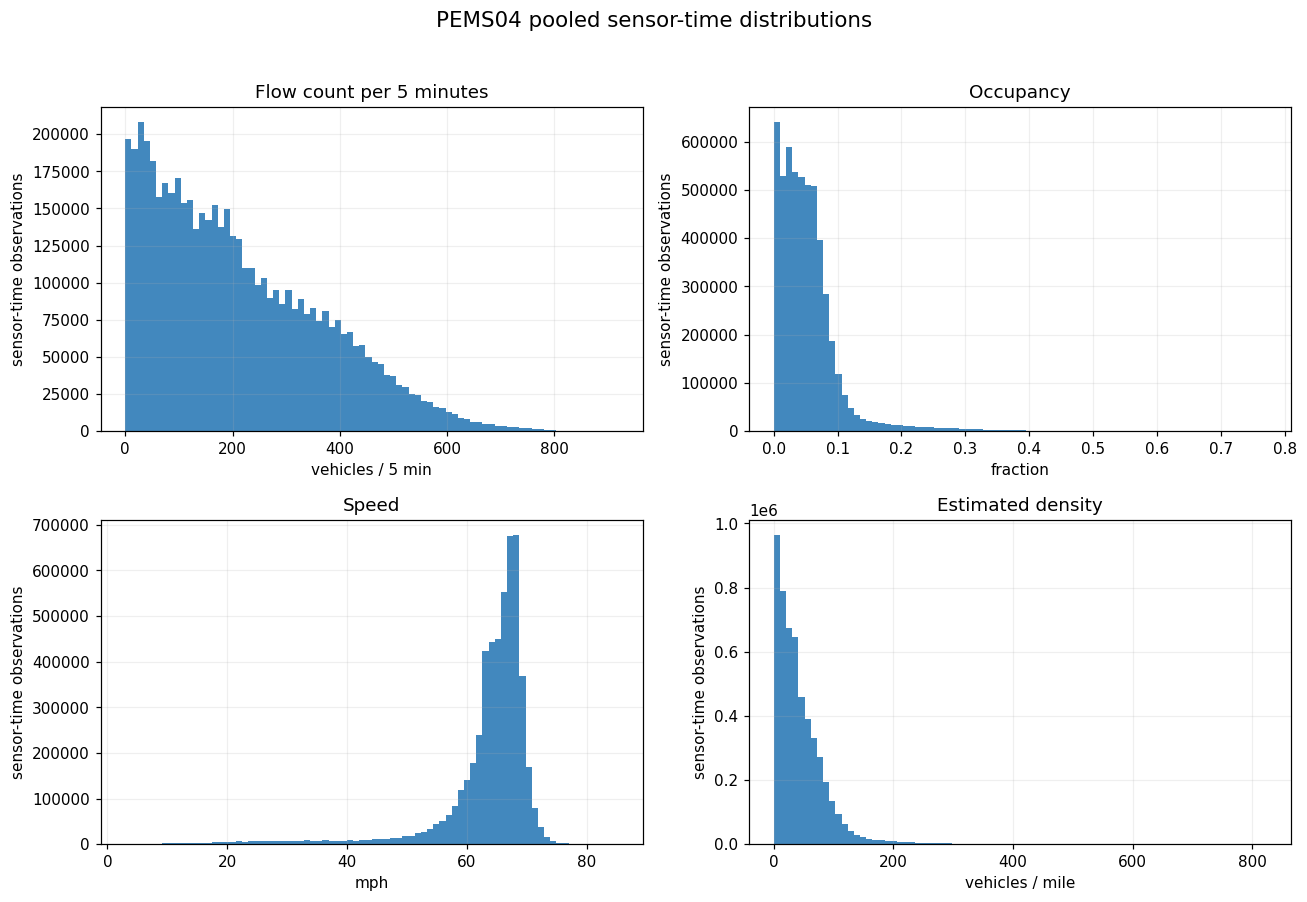

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
plot_specs = [
    (raw[:, :, 0], "Flow count per 5 minutes", "vehicles / 5 min"),
    (raw[:, :, 1], "Occupancy", "fraction"),
    (raw[:, :, 2], "Speed", "mph"),
    (density, "Estimated density", "vehicles / mile"),
]
for ax, (values, title, unit) in zip(axes.flat, plot_specs):
    ax.hist(values.ravel(), bins=80, color="#2878B5", alpha=0.88)
    ax.set_title(title)
    ax.set_xlabel(unit)
    ax.set_ylabel("sensor-time observations")
    ax.grid(alpha=0.2)
fig.suptitle("PEMS04 pooled sensor-time distributions", y=1.02, fontsize=14)
fig.tight_layout()
plt.show()


## 4. View network-wide trends

        Each point is the mean across sensors at one five-minute timestamp.


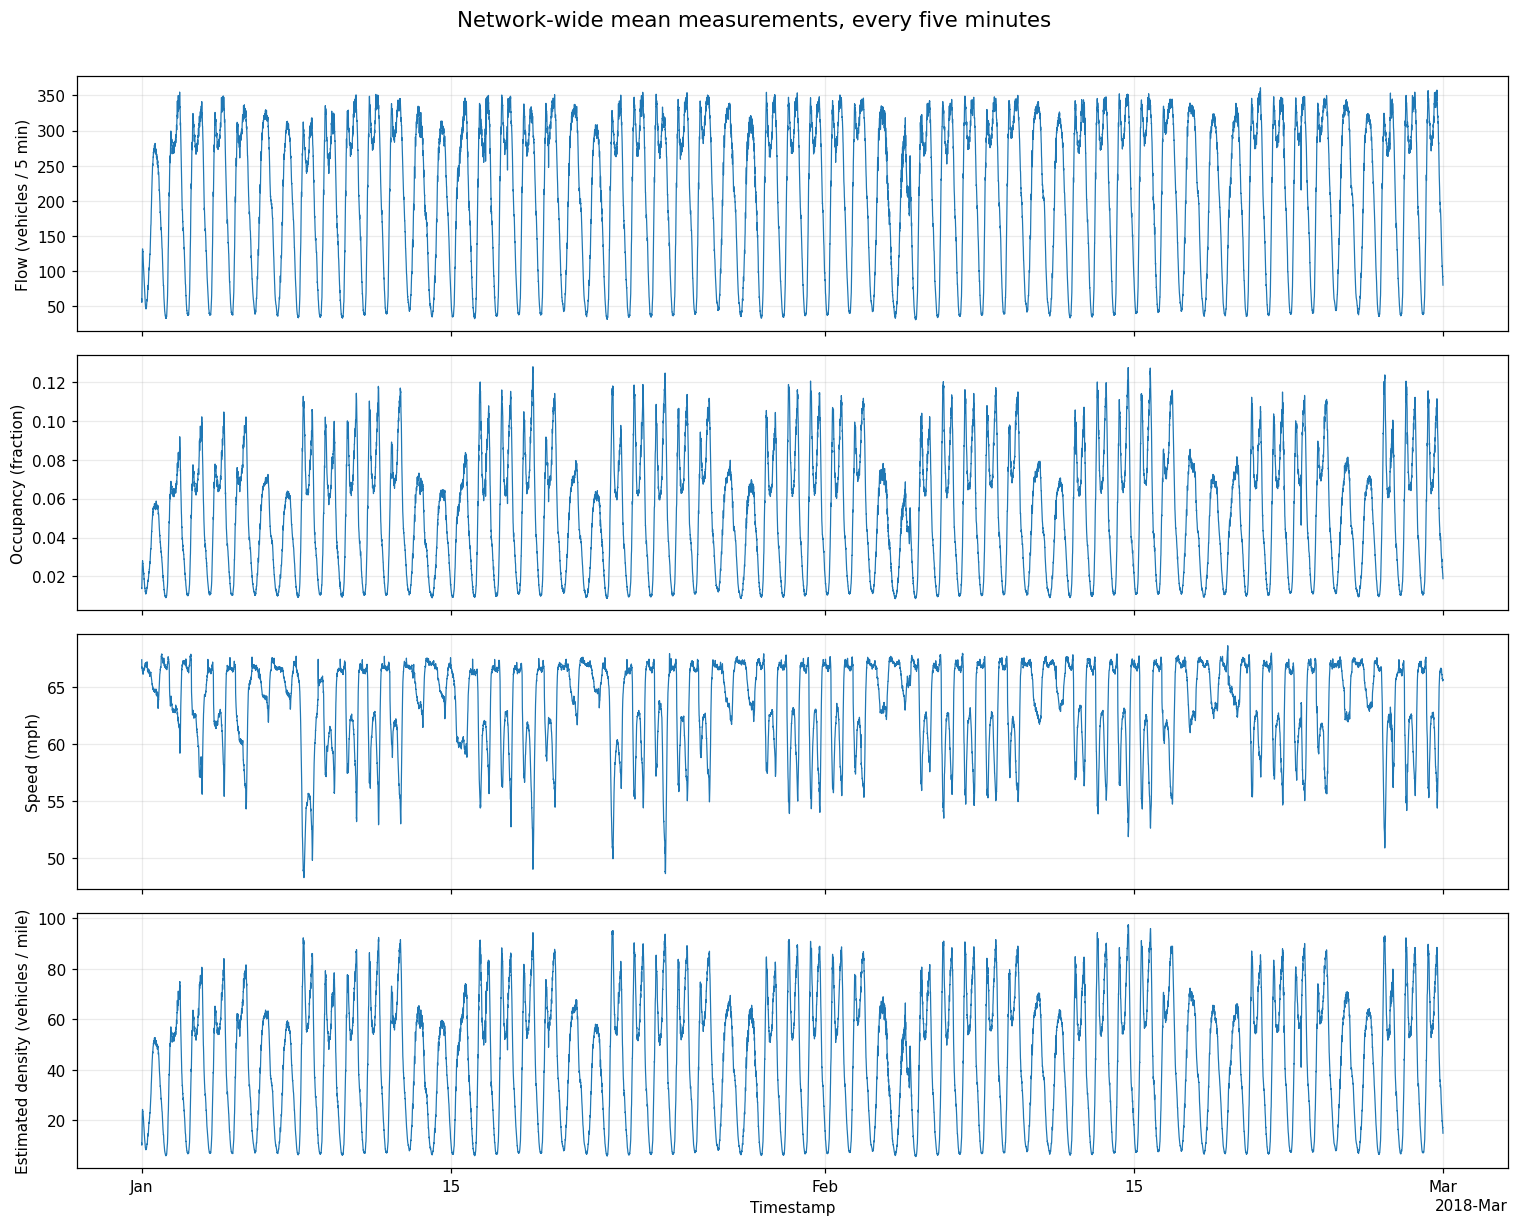

In [5]:
network_means = {
    "Flow (vehicles / 5 min)": raw[:, :, 0].mean(axis=1),
    "Occupancy (fraction)": raw[:, :, 1].mean(axis=1),
    "Speed (mph)": raw[:, :, 2].mean(axis=1),
    "Estimated density (vehicles / mile)": density.mean(axis=1),
}

fig, axes = plt.subplots(4, 1, figsize=(14, 11), sharex=True)
for ax, (label, values) in zip(axes, network_means.items()):
    ax.plot(timestamps, values, linewidth=0.8, color="#1f77b4")
    ax.set_ylabel(label)
    ax.grid(alpha=0.25)
axes[-1].xaxis.set_major_locator(mdates.AutoDateLocator(minticks=5, maxticks=9))
axes[-1].xaxis.set_major_formatter(mdates.ConciseDateFormatter(axes[-1].xaxis.get_major_locator()))
axes[-1].set_xlabel("Timestamp")
fig.suptitle("Network-wide mean measurements, every five minutes", y=1.01, fontsize=14)
fig.tight_layout()
plt.show()


## 5. Compare weekday profiles

        Readings are averaged by clock hour, weekday, and sensor. These profiles describe this two-month sample; they do not establish a causal weekday effect.


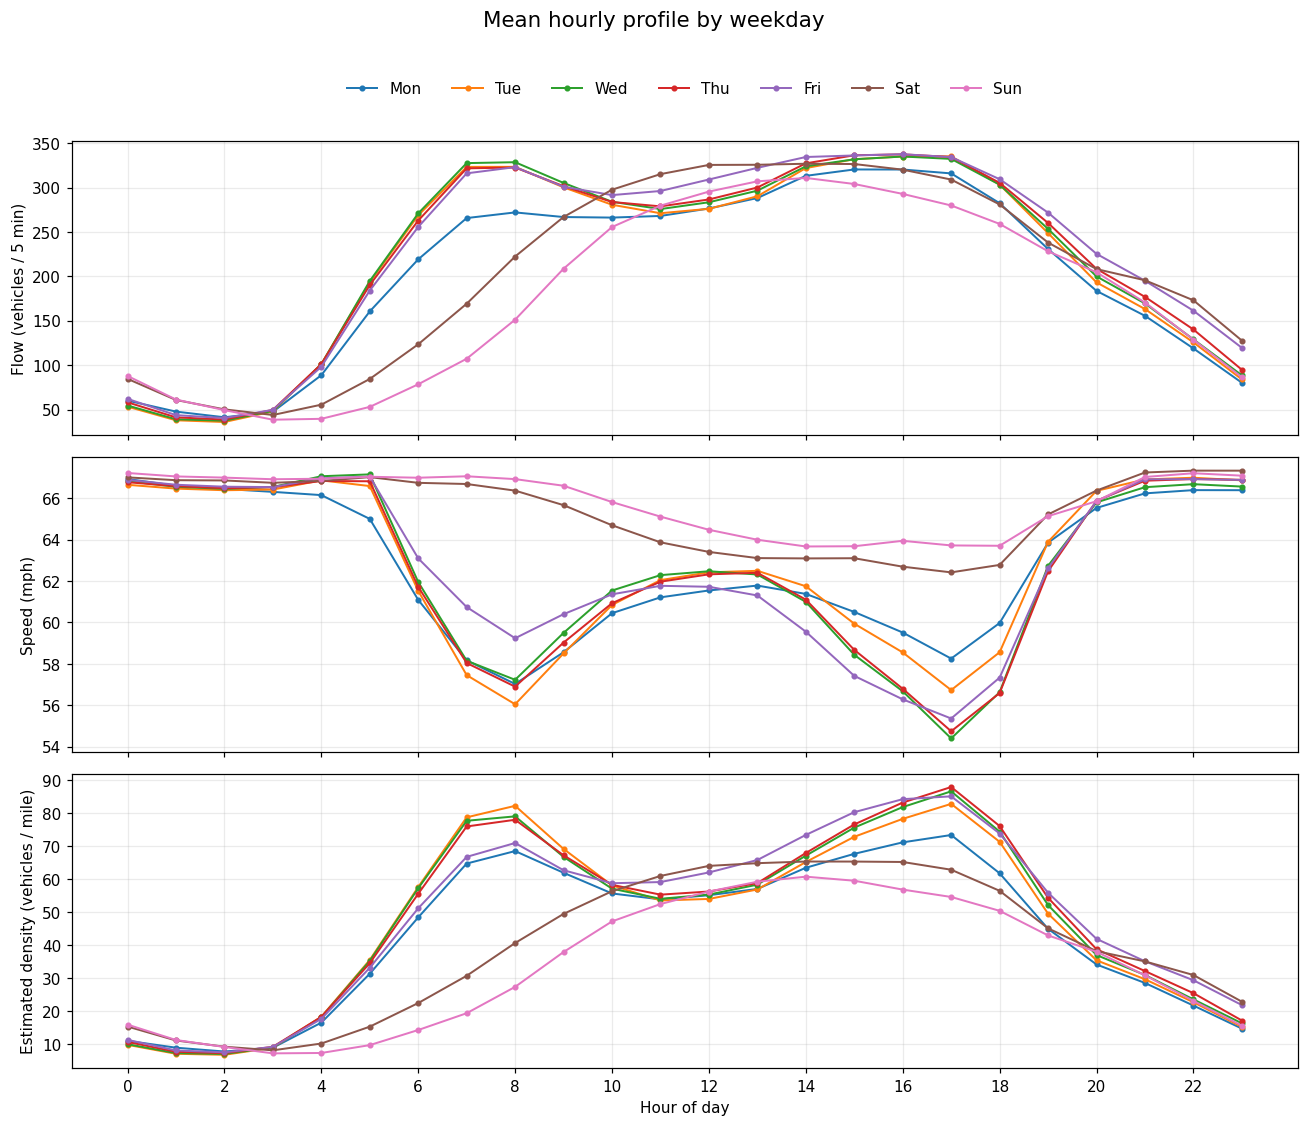

In [6]:
complete_steps = full_days * steps_per_day
raw_by_day = raw[:complete_steps].reshape(
    full_days, 24, 60 // INTERVAL_MINUTES, n_sensors, n_channels
)
density_by_day = density[:complete_steps].reshape(
    full_days, 24, 60 // INTERVAL_MINUTES, n_sensors
)
weekdays = np.array([
    (START_DATE + timedelta(days=day)).weekday()
    for day in range(full_days)
])

hourly_values = {
    "Flow (vehicles / 5 min)": raw_by_day[..., 0].mean(axis=(2, 3)),
    "Speed (mph)": raw_by_day[..., 2].mean(axis=(2, 3)),
    "Estimated density (vehicles / mile)": density_by_day.mean(axis=(2, 3)),
}
weekday_names = ("Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun")
weekday_profiles = {}
for label, daily_hourly_values in hourly_values.items():
    weekday_profiles[label] = np.stack([
        daily_hourly_values[weekdays == weekday].mean(axis=0)
        for weekday in range(7)
    ])

fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)
for ax, (label, profiles) in zip(axes, weekday_profiles.items()):
    for weekday, name in enumerate(weekday_names):
        ax.plot(range(24), profiles[weekday], marker=".", linewidth=1.3, label=name)
    ax.set_ylabel(label)
    ax.set_xticks(range(0, 24, 2))
    ax.grid(alpha=0.25)
axes[-1].set_xlabel("Hour of day")
axes[0].legend(ncol=7, loc="upper center", bbox_to_anchor=(0.5, 1.25), frameon=False)
fig.suptitle("Mean hourly profile by weekday", y=1.02, fontsize=14)
fig.tight_layout()
plt.show()


## 6. Compare sensors

        The horizontal axis is sensor index, not map position. Each summary uses the full date range.


Five sensors with the highest period-mean estimated density:
sensor  79: mean=121.68, p95=288.96 vehicles/mile
sensor  41: mean=109.47, p95=229.43 vehicles/mile
sensor  42: mean=100.13, p95=384.37 vehicles/mile
sensor  57: mean=99.10, p95=264.00 vehicles/mile
sensor 203: mean=98.86, p95=201.18 vehicles/mile


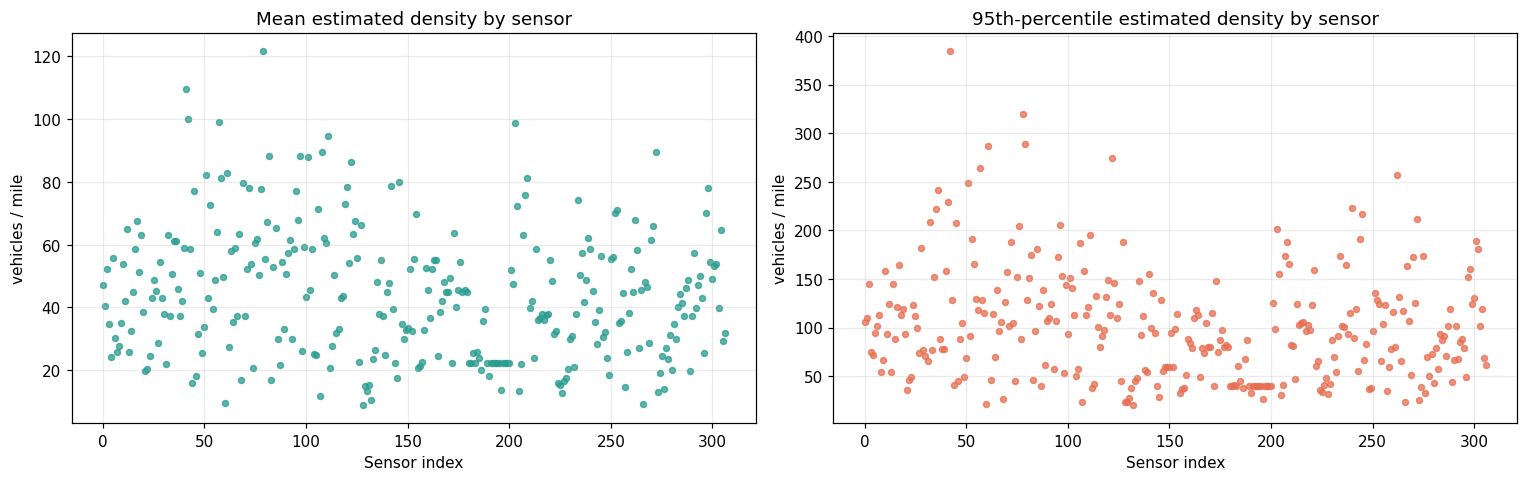

In [7]:
sensor_mean_density = density.mean(axis=0)
sensor_p95_density = np.quantile(density, 0.95, axis=0)
sensor_ids = np.arange(n_sensors)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].scatter(sensor_ids, sensor_mean_density, s=15, alpha=0.75, color="#2a9d8f")
axes[0].set_title("Mean estimated density by sensor")
axes[0].set_ylabel("vehicles / mile")
axes[1].scatter(sensor_ids, sensor_p95_density, s=15, alpha=0.75, color="#e76f51")
axes[1].set_title("95th-percentile estimated density by sensor")
axes[1].set_ylabel("vehicles / mile")
for ax in axes:
    ax.set_xlabel("Sensor index")
    ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

highest_mean = np.argsort(sensor_mean_density)[-5:][::-1]
print("Five sensors with the highest period-mean estimated density:")
for sensor in highest_mean:
    print(
        f"sensor {sensor:3d}: mean={sensor_mean_density[sensor]:.2f}, "
        f"p95={sensor_p95_density[sensor]:.2f} vehicles/mile"
    )


## 7. Explore channel relationships

        Correlations and scatterplots use a reproducible sample. Density is computed from flow and speed, so its correlations with those inputs are partly mathematical by construction.


Pearson correlation on a reproducible 100,000-row sample (or all rows if smaller):
                 Flow  Occupanc     Speed  Estimate
Flow            1.000     0.609    -0.334     0.839
Occupancy       0.609     1.000    -0.829     0.844
Speed          -0.334    -0.829     1.000    -0.707
Estimated density   0.839     0.844    -0.707     1.000


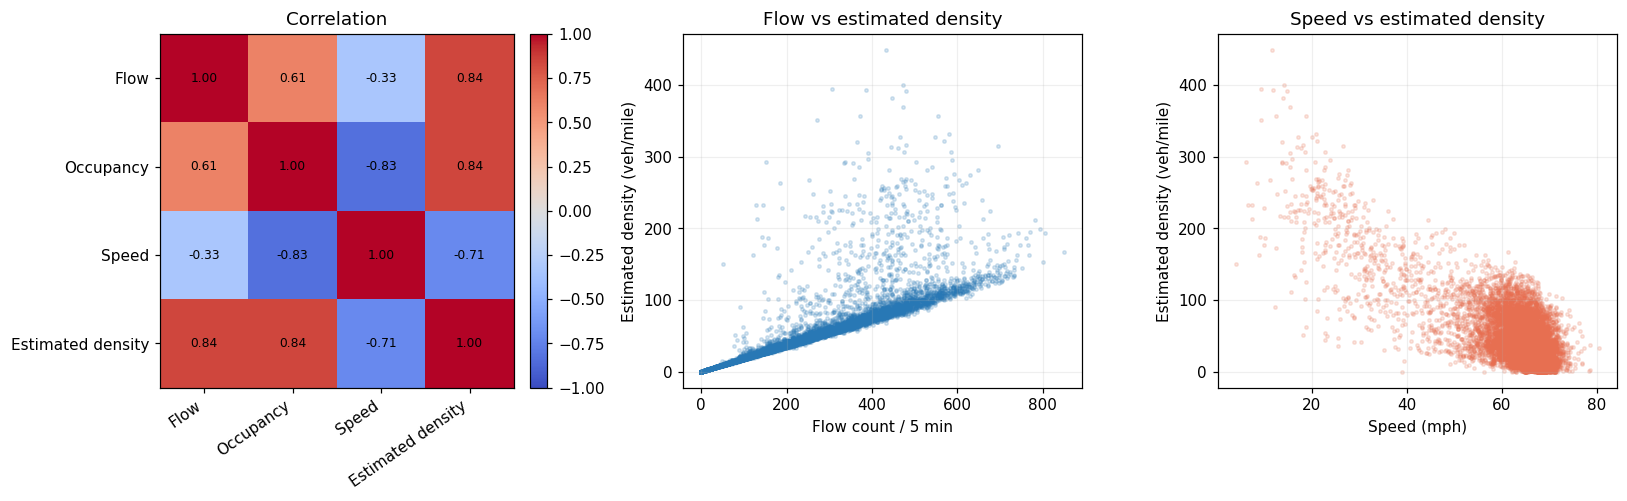

In [8]:
rng = np.random.default_rng(42)
total_rows = n_steps * n_sensors
sample_size = min(100_000, total_rows)
row_ids = rng.choice(total_rows, size=sample_size, replace=False)
flat_raw = raw.reshape(total_rows, n_channels)
flat_density = density.reshape(total_rows)
sampled = np.column_stack((flat_raw[row_ids], flat_density[row_ids]))
labels = ("Flow", "Occupancy", "Speed", "Estimated density")
correlation = np.corrcoef(sampled, rowvar=False)

print("Pearson correlation on a reproducible 100,000-row sample (or all rows if smaller):")
print("             " + "  ".join(f"{label[:8]:>8s}" for label in labels))
for label, row in zip(labels, correlation):
    print(f"{label:13s}" + "  ".join(f"{value:8.3f}" for value in row))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
image = axes[0].imshow(correlation, vmin=-1, vmax=1, cmap="coolwarm")
axes[0].set_xticks(range(4), labels, rotation=35, ha="right")
axes[0].set_yticks(range(4), labels)
axes[0].set_title("Correlation")
for row in range(4):
    for col in range(4):
        axes[0].text(col, row, f"{correlation[row, col]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(image, ax=axes[0], fraction=0.046, pad=0.04)

scatter_ids = rng.choice(sample_size, size=min(12_000, sample_size), replace=False)
axes[1].scatter(sampled[scatter_ids, 0], sampled[scatter_ids, 3], s=5, alpha=0.18, color="#2878B5")
axes[1].set_xlabel("Flow count / 5 min")
axes[1].set_ylabel("Estimated density (veh/mile)")
axes[1].set_title("Flow vs estimated density")

axes[2].scatter(sampled[scatter_ids, 2], sampled[scatter_ids, 3], s=5, alpha=0.18, color="#e76f51")
axes[2].set_xlabel("Speed (mph)")
axes[2].set_ylabel("Estimated density (veh/mile)")
axes[2].set_title("Speed vs estimated density")
for ax in axes[1:]:
    ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()


## 8. Notes for modeling

        - Flow, occupancy, and speed use different units and have different ranges; inspect and scale them deliberately.
        - Network averages reveal time patterns, while sensor summaries show substantial differences across locations.
        - The sensor graph supports neighborhood aggregation; it is not a vehicle-routing map.
        - Density is derived, not independently measured. Report forecasts as accuracy against derived density labels.
        - Keep forecasting splits chronological and build every feature from observations at or before its prediction time.
